# Heart Disease Risk Modelling — Phase 1: EDA and Classical Models
**Advanced Machine Learning · Project 15** &nbsp;|&nbsp; Bayesian networks, Naive Bayes and classical baselines on the UCI Cleveland data

| Student | Enrollment no. |
|---|---|
| Aaryan Yadav | 2401010011 |
| Shivam Mishra | 2401010442 |
| Satyam Kumar | 2401010429 |
| Himank Kaushik | 2401010187 |
| Mohammed Yaseen | 2401010281 |

> **Scope.** This notebook is **Phase 1 (Advanced ML)**: exploratory data analysis, leak-free preprocessing, documented discretisation, a hand-specified Bayesian network (pgmpy), Naive Bayes, and classical reference models, all compared with repeated stratified cross-validation (ROC AUC, PR AUC, sensitivity, specificity, calibration). The regularised MLP and SHAP comparison belong to **Phase 2 (Deep Learning)** and are intentionally not included here.
>
> **Disclaimer.** This is a prediction exercise on a historical research dataset, *not* clinical decision support. Predicted risks must not be read as medical recommendations.

**Notebook map:** 1 Data & target · 2 EDA · 3 Preprocessing & discretisation · 4 Models · 5 Evaluation protocol · 6 Results · 7 Ablations & sensitivity · 8 Interpreting the Bayesian network · 9 Findings, gap analysis, limitations, hand-off to Phase 2

In [1]:
%matplotlib inline
import sys, time, warnings; warnings.filterwarnings("ignore", category=FutureWarning, module="pgmpy"); sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from pathlib import Path
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, mutual_info_score
from data import *
RES = Path("../results"); FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED, K, R, B = 2026, 5, 5, 500
POS, NEG, BLUE, AMBER, GREY = "#e63946", "#2a9d8f", "#2a6f97", "#d98e04", "#6c757d"
def save(name): plt.tight_layout(); plt.savefig(FIG / name, dpi=150); plt.show()

## 1. Data and target definition
Source: UCI Heart Disease repository, **processed Cleveland** file (`data/processed.cleveland.data`, SHA-256 `a74b7efa…27c8`). 303 patients, 13 predictors and the 0–4 angiographic label `num`.

In [2]:
df = load()
schema = pd.DataFrame({"variable": FEATURES, "type": ["numeric"]*5 + ["categorical"]*8, "meaning": [
 "age in years", "resting blood pressure (mmHg)", "serum cholesterol (mg/dl)", "maximum heart rate achieved (bpm)", "exercise-induced ST depression (mm)",
 "sex (1 = male, 0 = female)", "chest pain type (1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic)", "fasting blood sugar > 120 mg/dl (1 = yes)",
 "resting ECG (0 normal, 1 ST-T abnormality, 2 LV hypertrophy)", "exercise-induced angina (1 = yes)", "slope of peak-exercise ST segment (1 up, 2 flat, 3 down)",
 "major vessels coloured by fluoroscopy (0–3)", "thallium scan (3 normal, 6 fixed defect, 7 reversible defect)"]})
display(schema)
print("Target definition: y = 1 if num >= 1 (angiographic narrowing > 50% in any major vessel), else 0")
print(df["num"].value_counts().sort_index().to_dict(), "->", df["target"].value_counts().sort_index().to_dict(), f"(prevalence {df.target.mean():.3f})")
miss = df[FEATURES].isna().sum(); print("Missing values:", miss[miss > 0].to_dict(), "| rows affected:", int(df[FEATURES].isna().any(axis=1).sum()))
df.head()

,variable,type,meaning
0,age,numeric,age in years
1,trestbps,numeric,resting blood pressure (mmHg)
2,chol,numeric,serum cholesterol (mg/dl)
3,thalach,numeric,maximum heart rate achieved (bpm)
4,oldpeak,numeric,exercise-induced ST depression (mm)
5,sex,categorical,"sex (1 = male, 0 = female)"
6,cp,categorical,"chest pain type (1 typical angina, 2 atypical,..."
7,fbs,categorical,fasting blood sugar > 120 mg/dl (1 = yes)
8,restecg,categorical,"resting ECG (0 normal, 1 ST-T abnormality, 2 L..."
9,exang,categorical,exercise-induced angina (1 = yes)


Target definition: y = 1 if num >= 1 (angiographic narrowing > 50% in any major vessel), else 0
{0: 164, 1: 55, 2: 36, 3: 35, 4: 13} -> {0: 164, 1: 139} (prevalence 0.459)
Missing values: {'ca': 4, 'thal': 2} | rows affected: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


**Missingness and row independence.** `ca` has 4 missing values and `thal` has 2, across 6 rows. The Bayesian estimator uses locally available node/parent counts (not EM); missing evidence is marginalised at prediction. Other models impute within each training fold. There are no exact duplicate predictor rows. The processed file has no usable patient identifiers, so one-row-per-patient independence is an assumption, not independently verified.

## 2. Exploratory data analysis

### 2.1 Class balance and sex

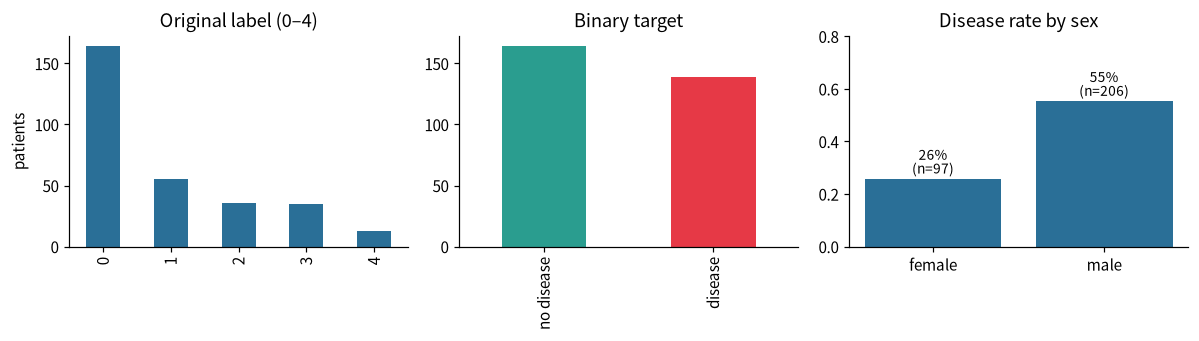

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
df["num"].value_counts().sort_index().plot.bar(ax=ax[0], color=BLUE); ax[0].set(title="Original label (0–4)", xlabel="", ylabel="patients")
df["target"].map({0: "no disease", 1: "disease"}).value_counts().plot.bar(ax=ax[1], color=[NEG, POS]); ax[1].set(title="Binary target", xlabel="")
r = df.groupby("sex").target.agg(["mean", "size"]); ax[2].bar(["female", "male"], r["mean"], color=BLUE)
for i, (m, n) in enumerate(zip(r["mean"], r["size"])): ax[2].text(i, m + .02, f"{m:.0%}\n(n={n})", ha="center", fontsize=9)
ax[2].set(title="Disease rate by sex", ylim=(0, .8)); save("fig_eda_balance.png")

### 2.2 Numeric variables by outcome

age       trestbps           chol        thalach        oldpeak      
         mean   std     mean    std    mean    std    mean    std    mean   std
target                                                                         
0       52.59  9.51   129.25  16.20  242.64  53.46  158.38  19.20    0.59  0.78
1       56.63  7.94   134.57  18.77  251.47  49.49  139.26  22.59    1.57  1.30

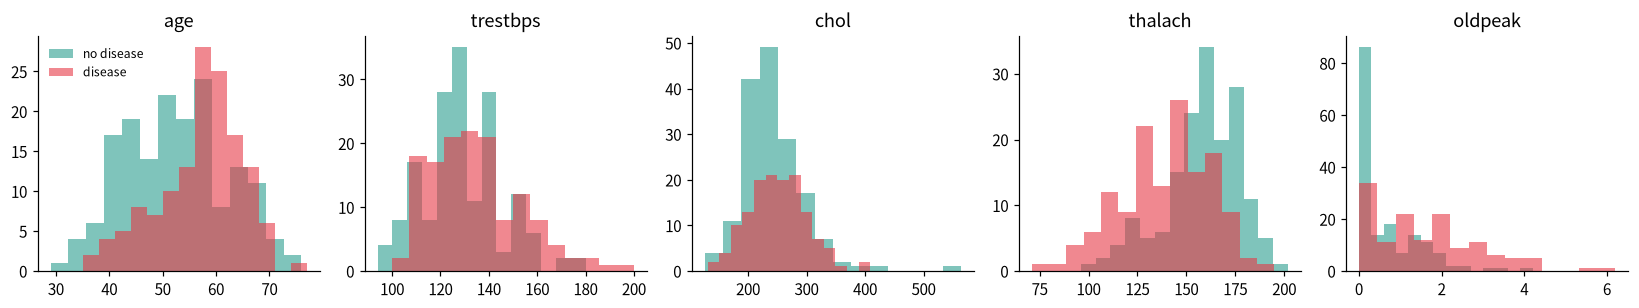

In [4]:
display(df.groupby("target")[NUM].agg(["mean", "std"]).round(2))
fig, ax = plt.subplots(1, 5, figsize=(15, 2.9))
for a, v in zip(ax, NUM):
    for t, c, l in [(0, NEG, "no disease"), (1, POS, "disease")]: a.hist(df[v][df.target == t], bins=14, alpha=.6, color=c, label=l)
    a.set_title(v)
ax[0].legend(frameon=False, fontsize=8); save("fig_eda_numeric.png")

### 2.3 Categorical variables — disease rate per category

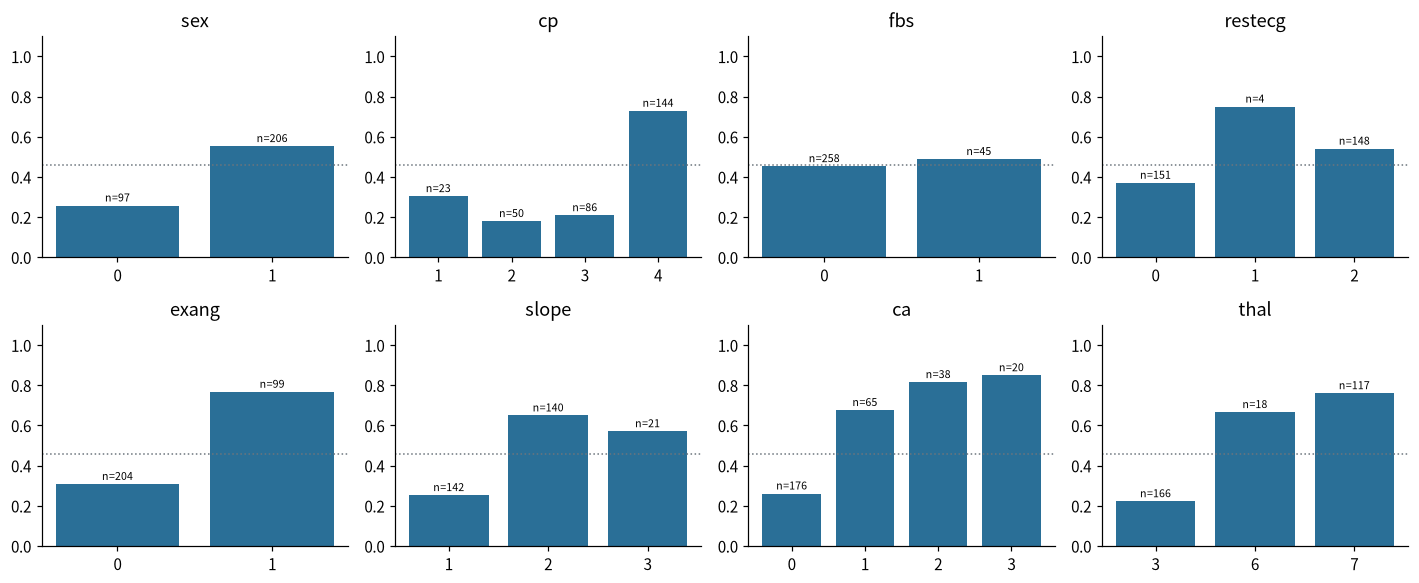

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(13, 5.4))
for a, v in zip(ax.ravel(), CAT):
    g = df.groupby(v).target.agg(["mean", "size"]); a.bar(g.index.astype(int).astype(str), g["mean"], color=BLUE)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(i, m + .02, f"n={n}", ha="center", fontsize=7)
    a.set(title=v, ylim=(0, 1.1)); a.axhline(df.target.mean(), color=GREY, ls=":", lw=1)
save("fig_eda_categorical.png")

### 2.4 Correlations and the age–heart-rate relationship

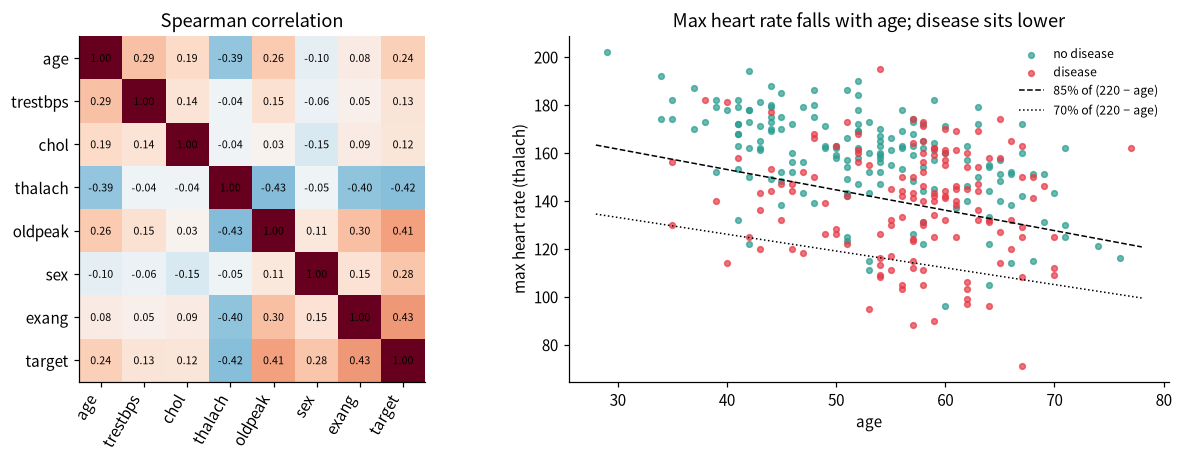

In [6]:
cm = df[NUM + ["sex", "exang", "target"]].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.1]})
im = ax[0].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1); ax[0].set_xticks(range(len(cm))); ax[0].set_xticklabels(cm.columns, rotation=60, ha="right"); ax[0].set_yticks(range(len(cm))); ax[0].set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)): ax[0].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax[0].set_title("Spearman correlation")
for t, c, l in [(0, NEG, "no disease"), (1, POS, "disease")]: ax[1].scatter(df.age[df.target == t], df.thalach[df.target == t], s=14, c=c, alpha=.7, label=l)
xs = np.linspace(28, 78, 50)
for pct, ls in [(.85, "--"), (.70, ":")]: ax[1].plot(xs, pct * (220 - xs), "k", ls=ls, lw=1, label=f"{pct:.0%} of (220 − age)")
ax[1].set(xlabel="age", ylabel="max heart rate (thalach)", title="Max heart rate falls with age; disease sits lower"); ax[1].legend(frameon=False, fontsize=8)
save("fig_eda_corr_hr.png")

### 2.5 Which variables carry univariate signal? (exploratory only)
Computed on the full data purely to *understand* the data. It is **not** used for feature selection or model choice (that would leak).

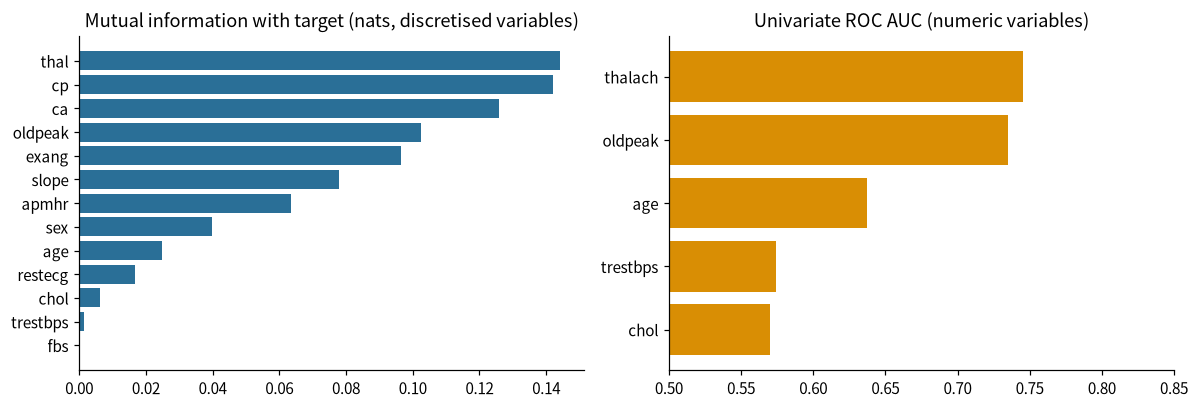

top-5 MI: {'thal': 0.144, 'cp': 0.142, 'ca': 0.126, 'oldpeak': 0.102, 'exang': 0.096}


In [7]:
Xd_full = discretize(df); mi = {}
for v in DISC_FEATURES: mi[v] = mutual_info_score(Xd_full[v].fillna(-1).astype(str), df.target)
auc_num = {v: max(roc_auc_score(df.target, df[v]), 1 - roc_auc_score(df.target, df[v])) for v in NUM}
mi = pd.Series(mi).sort_values(); fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].barh(mi.index, mi.values, color=BLUE); ax[0].set(title="Mutual information with target (nats, discretised variables)")
a = pd.Series(auc_num).sort_values(); ax[1].barh(a.index, a.values, color=AMBER); ax[1].set(title="Univariate ROC AUC (numeric variables)", xlim=(.5, .85))
save("fig_eda_signal.png"); print("top-5 MI:", mi.sort_values(ascending=False).head(5).round(3).to_dict())

### 2.6 EDA takeaways
The displayed charts describe this small, historical dataset. Work-up variables such as `ca` and `thal` have strong associations with the existing diagnosis. Associations are not causal effects. The supplied graph and HR transformation are motivated partly by EDA; this is an exploratory project, not a preregistered confirmatory evaluation.

## 3. Preprocessing and discretisation
Cut points are constants in the supplied code, not fit on validation data. They are modelling choices and not diagnostic criteria. Bins are right-open `[a,b)` with infinite outer boundaries. The age-predicted HR expression is a rough feature transformation, not a test for chronotropic incompetence.

,variable,states,interior cut points,rationale
0,age,<50 | 50-59 | >=60,"50, 60",decade-style risk bands
1,trestbps,<130 | >=130,130,fixed modelling split at 130 mmHg; not a diagn...
2,chol,<240 | >=240,240,fixed modelling split at 240 mg/dl
3,apmhr,<70% | 70-84% | >=85%,"0.7, 0.85",rough age-adjusted HR feature; not a diagnosti...
4,oldpeak,<1mm | 1-<2mm | >=2mm,"1, 2",fixed splits at 1 and 2 in supplied ST-depress...


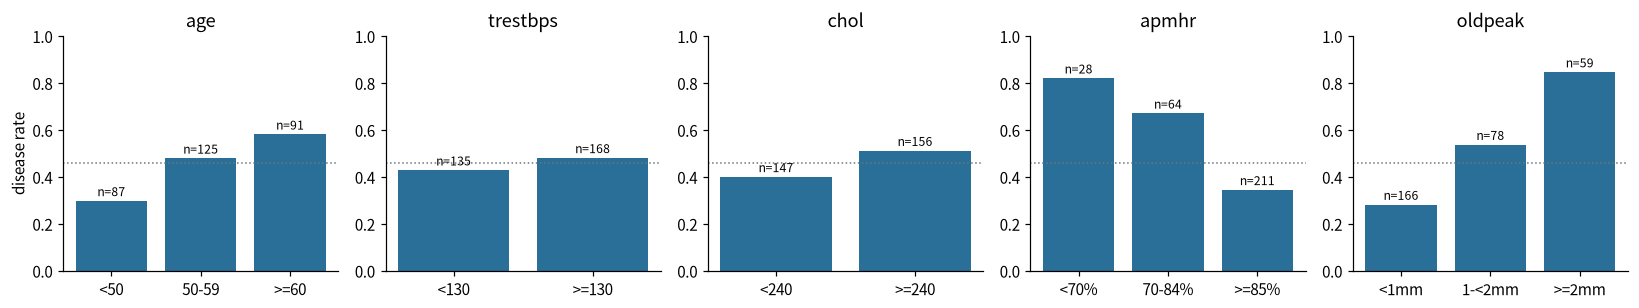

In [8]:
cp = cutpoint_table(); cp["rationale"] = ["decade-style risk bands", "fixed modelling split at 130 mmHg; not a diagnosis", "fixed modelling split at 240 mg/dl",
  "rough age-adjusted HR feature; not a diagnostic criterion", "fixed splits at 1 and 2 in supplied ST-depression units"]
display(cp); cp.to_csv(RES / "phase1_cutpoints.csv", index=False)
fig, ax = plt.subplots(1, 5, figsize=(15, 2.9)); rows = []
for a, v in zip(ax, DISC_NUM):
    g = pd.DataFrame({"bin": Xd_full[v], "y": df.target}).groupby("bin").y.agg(["mean", "size"]).reindex(STATES[v])
    a.bar(g.index, g["mean"], color=BLUE); a.set(title=v, ylim=(0, 1)); a.axhline(df.target.mean(), color=GREY, ls=":", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(i, m + .02, f"n={n}", ha="center", fontsize=8)
ax[0].set_ylabel("disease rate"); save("fig_bin_rates.png")

**Reading the bin plots.** The bars show full-dataset associations and small-bin counts. They do not prove these cut points are optimal or clinically valid. No cut-point search was performed during this audit.

**Leakage safeguards:** training-fold imputation and scaling; identical held-out row indices; fixed model settings; missing evidence omitted for BN inference; threshold 0.5 not selected from validation outcomes. Full-data EDA informed some design choices in the supplied work, so model-selection optimism remains possible. We cannot establish that the original choices were made before seeing results.